# Task 2: Bengali ASR

Sahil al Farib, AIMScribe RA (Speech AI) assessment.

| Step | Result checked |
|---|---|
| 1. OpenSLR 53 subset: 16 kHz, silence trim, text normalisation, speaker-disjoint split | split identical |
| 2. whisper-small zero-shot | WER 144.1 / CER 135.7 |
| 3. My whisper-small fine-tune | 66.4 / 21.4 |
| 4. Errors on my real consultations | error types, hallucination, noise |
| 5. Fixes: token budget, VAD gate | CER 41.6 → 39.2, hallucination 19 → 0 |
| 6. Model selection | 600M CER 7.2 |
| 7. Clinical test (600 synthetic clips) | term accuracy 71 % |
| 8. My clinical fine-tune of IndicConformer 120M | CER 11.1 → 9.4, terms 52 → 71 % |

My fine-tuned models are downloaded from Hugging Face, not re-trained. The training code is in steps 3 and 8
(`RUN_WHISPER_FINETUNE`, `RUN_CLINICAL_FINETUNE`).

Runtime on a T4: ~1 h. WER / CER after the same normalisation for all models (`data/common.py`).

## Setup

1. Runtime → Change runtime type → **T4 GPU**.
2. Add your Hugging Face token to Colab **Secrets** as `HF_TOKEN`.
3. Accept the terms of these models / datasets with that account: [ai4bharat/indic-conformer-600m-multilingual](https://huggingface.co/ai4bharat/indic-conformer-600m-multilingual); for step 8 also [ai4bharat/indicconformer_stt_bn_hybrid_ctc_rnnt_large](https://huggingface.co/ai4bharat/indicconformer_stt_bn_hybrid_ctc_rnnt_large) and [ai4bharat/IndicF5](https://huggingface.co/ai4bharat/IndicF5).

Then Runtime → Run all. The code is cloned from GitHub; models and public data are downloaded.

Each step re-runs an experiment and `check(...)` compares the new number with the submitted one (kept in
`/content/submitted_results`). The table at the end lists all checks. If the runtime disconnects, run all again:
finished steps are skipped.

In [2]:
REPO_URL = "https://github.com/sahilaf/Aimscribe"
# my fine-tuned models (Hugging Face repo id or local path)
FT_WHISPER = "sahilfarib/aimscribe-whisper-small-bn"
FT_120M = "sahilfarib/aimscribe-indicconformer-120m-bn-clinical"
RUN_120M = True                 # step 8 (~25 min)
RUN_WHISPER_FINETUNE = False    # re-train whisper-small (~35 min)
RUN_CLINICAL_FINETUNE = False   # re-make the training audio and re-train the 120M (~4 h)
import filecmp, json, os, re, shutil, subprocess, zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Audio, Image, Markdown, display
from google.colab import userdata

REPO, DATA = "/content/aimscribe", "/content/aimscribe_data"     # code + labels | audio + models
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, REPO], check=True)
os.makedirs(DATA, exist_ok=True)
os.environ.update(HF_TOKEN=userdata.get("HF_TOKEN"), AIMSCRIBE_DATA=DATA)
SUB, NEW = "/content/submitted_results", f"{REPO}/results"
if not os.path.exists(SUB):
    shutil.copytree(NEW, SUB)                                     # untouched copy of the submitted results
def sh(cmd, tail=None):
    """Run a shell command from the repository root; stop the notebook if it fails.
    tail=N prints only the last N lines (long runs). Library warnings are filtered out."""
    p = subprocess.run(cmd, shell=True, executable="/bin/bash", cwd=REPO, text=True, env=dict(os.environ, MPLBACKEND="Agg"),
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = [l for l in p.stdout.splitlines() if not re.search(r"[Ww]arning|warnings\.warn|FRAME_DURATION", l)]
    print("\n".join(lines[-tail:] if tail else lines))
    if p.returncode:
        raise RuntimeError(f"command failed ({p.returncode}): {cmd}")


def fresh(task, run, cmd, tail=2):
    """Run `cmd` once for results/<task>/<run>: the submitted output is deleted first, so a check can never pass on
    submitted files; a marker skips the run after a disconnect."""
    marker = f"/content/.done_task2_{run}"
    if not os.path.exists(marker):
        shutil.rmtree(f"{NEW}/task2/{run}", ignore_errors=True)
        sh(cmd, tail=tail)
        Path(marker).touch()


CHECKS = []
def check(what, submitted, reproduced, tol=0.15):
    """Compare a reproduced number with the submitted one (absolute tolerance, same unit)."""
    ok = reproduced is not None and abs(float(reproduced) - float(submitted)) <= tol
    CHECKS.append({"result": what, "submitted": submitted, "reproduced": reproduced, "tolerance": tol,
                   "match": "✓" if ok else "✗"})
    print(f"{'✓' if ok else '✗'}  {what}: submitted {submitted} | reproduced {reproduced}")


def show_images(paths, titles=None, cols=1, width=16, row_h=3.2):
    """Show saved PNG figures inline (one per row by default)."""
    import matplotlib.image as mpimg
    paths = [p for p in paths if os.path.exists(p)]
    rows = -(-len(paths) // cols)
    fig, axes = plt.subplots(rows, cols, figsize=(width, row_h * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, p in enumerate(paths):
        ax = axes.flat[i]
        ax.imshow(mpimg.imread(p))
        ax.set_title(titles[i] if titles else Path(p).stem, fontsize=10)
    plt.tight_layout(); plt.show()


sh("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader")

Tesla T4, 15360 MiB


`model_path` takes a local path or a Hugging Face repo id (downloaded once).

In [3]:
sh("pip install -q uv && uv python install 3.12", tail=2)
def venv(name, py="3.12"):
    if not os.path.exists(f"/content/{name}/bin/python"):
        sh(f"uv venv -q --seed --python-preference only-managed --python {py} /content/{name}")
    return f"/content/{name}/bin/python"

EVAL = venv("venv_eval")      # laptop pins: torch 2.5.1, pyannote.audio 3.3.2, transformers 4.46.3, onnxruntime 1.20.1
sh(f"uv pip install -q --python {EVAL} torch==2.5.1 torchaudio==2.5.1 --index-url https://download.pytorch.org/whl/cu121")
sh(f"uv pip install -q --python {EVAL} -r requirements.txt -c constraints.txt")
sh(f"{EVAL} -c 'import torch, pyannote.audio, transformers; print(\"eval env OK | torch\", torch.__version__, \"| pyannote\", pyannote.audio.__version__)'")


def model_path(spec, filename=None):
    """Local path for a model setting: an existing path as it is, or a Hugging Face repo id (downloaded once)."""
    if os.path.exists(spec):
        return spec
    from huggingface_hub import hf_hub_download, snapshot_download
    local = f"{DATA}/checkpoints/{spec.split('/')[-1]}"
    if filename:
        return hf_hub_download(spec, filename, local_dir=local, token=os.environ["HF_TOKEN"])
    return snapshot_download(spec, local_dir=local, token=os.environ["HF_TOKEN"])

Installed Python 3.12.15 in 1.17s
 + cpython-3.12.15-linux-x86_64-gnu (python3.12)



  sep="\s+",
  sep="\s+",
  sep="\s+",
  data = pd.read_csv(file_uem, names=names, dtype=dtype, sep="\s+")
  data = pd.read_csv(path, names=names, dtype=dtype, sep="\s+")
  file_trial, sep="\s+", names=["reference", "uri1", "uri2"]
  ctm, names=names, dtype=dtype, sep="\s+"
  mapping, names=names, dtype=dtype, sep="\s+"
eval env OK | torch 2.5.1+cu121 | pyannote 3.3.2


## 1. Data: OpenSLR 53

Part 0 of the corpus. Lines with digits or Latin letters dropped; speaker-disjoint split (train 80 min / 65 speakers,
test 18 min / 15 speakers); 16 kHz mono, long silences trimmed; text normalised (NFC, punctuation removed).

In [4]:
RAW = f"{DATA}/raw"
os.makedirs(RAW, exist_ok=True)
MIRRORS = ["https://www.openslr.org/resources/53", "https://us.openslr.org/resources/53", "https://openslr.elda.org/resources/53"]
for f in ["utt_spk_text.tsv", "asr_bengali_0.zip"]:              # transcripts + part 0 of the corpus (~920 MB)
    if not os.path.exists(f"{RAW}/{f}"):
        for m in MIRRORS:
            if subprocess.run(f"wget -q -O {RAW}/{f}.part {m}/{f} && mv {RAW}/{f}.part {RAW}/{f}", shell=True).returncode == 0:
                break
    print(f, os.path.getsize(f"{RAW}/{f}") // 2**20, "MB")

utt_spk_text.tsv 15 MB
asr_bengali_0.zip 877 MB


In [5]:
shutil.copytree(f"{REPO}/data/asr", "/content/submitted_data/asr", dirs_exist_ok=True)
sh(f"{EVAL} data/prepare_asr.py --train_minutes 90 --test_minutes 20", tail=8)
for f in ["train.csv", "test.csv"]:
    print(f, "identical to submitted:", filecmp.cmp(f"/content/submitted_data/asr/{f}", f"{REPO}/data/asr/{f}", shallow=False))
print(json.load(open(f"{REPO}/data/asr/stats.json")))
pd.read_csv(f"{REPO}/data/asr/train.csv").head()

  "test_utts": 390,
  "test_speakers": 15,
  "test_minutes": 18.2,
  "train_utts": 1623,
  "train_speakers": 65,
  "train_minutes": 79.9,
  "speaker_overlap_train_test": 0
}
train.csv identical to submitted: True
test.csv identical to submitted: True
{'dropped_text': 645, 'test_utts': 390, 'test_speakers': 15, 'test_minutes': 18.2, 'train_utts': 1623, 'train_speakers': 65, 'train_minutes': 79.9, 'speaker_overlap_train_test': 0}


,path,text,speaker,duration
0,asr/train/0012321d7b.wav,প্রিয় শাবিপ্রবির উদ্দেশে,11915,2.76
1,asr/train/029aec0dca.wav,শিশুটিকে একটা কুয়ার মধ্যে,11915,3.09
2,asr/train/04ee2c524d.wav,আবদুল জলিলের,11915,2.41
3,asr/train/055d696e4a.wav,মোগল ই আযমের প্রেমে,11915,3.21
4,asr/train/066ea52451.wav,একই সময়ে ঋণপত্র নিষ্পত্তি হয়েছে,11915,3.20


One clip before and after preprocessing:

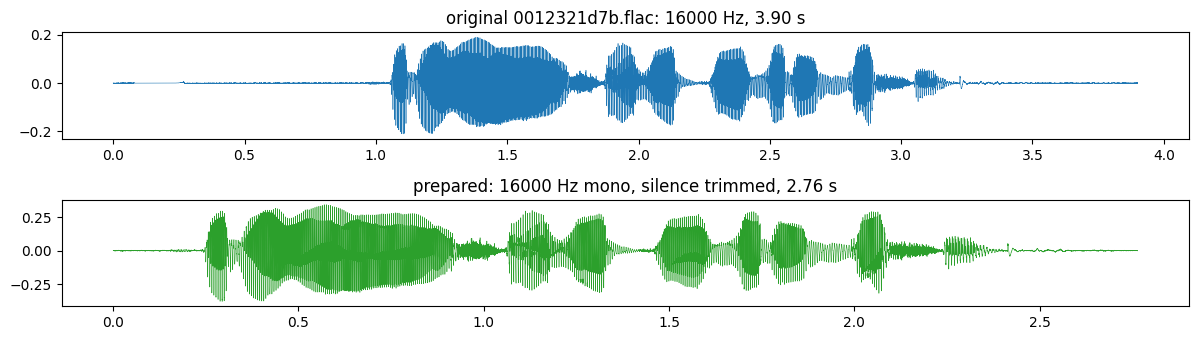

transcript (corpus): প্রিয় শাবিপ্রবির উদ্দেশে
normalised         : প্রিয় শাবিপ্রবির উদ্দেশে


In [6]:
import sys, numpy as np, soundfile as sf, matplotlib.pyplot as plt
sys.path.insert(0, f"{REPO}/data")
from common import normalize_bn, read_transcripts
row = pd.read_csv(f"{REPO}/data/asr/train.csv").iloc[0]
utt = Path(row.path).stem
raw_path = next(Path(f"{RAW}/extracted").rglob(f"{utt}.flac"))
raw, sr_raw = sf.read(raw_path)
proc, sr = sf.read(f"{DATA}/{row.path}")
original = {r["utt"]: r["text"] for r in read_transcripts(Path(f"{RAW}/utt_spk_text.tsv"))}[utt]
fig, ax = plt.subplots(2, 1, figsize=(12, 3.5))
ax[0].plot(np.arange(len(raw)) / sr_raw, raw, lw=0.4); ax[0].set_title(f"original {raw_path.name}: {sr_raw} Hz, {len(raw)/sr_raw:.2f} s")
ax[1].plot(np.arange(len(proc)) / sr, proc, lw=0.4, color="C2"); ax[1].set_title(f"prepared: {sr} Hz mono, silence trimmed, {len(proc)/sr:.2f} s")
plt.tight_layout(); plt.show()
print("transcript (corpus):", original)
print("normalised         :", normalize_bn(original))

## 2. Baseline: whisper-small zero-shot

In [7]:
sh(f"{EVAL} task2_asr/evaluate_asr.py --model openai/whisper-small --run baseline_small", tail=4)
s, n = (json.load(open(f"{r}/task2/baseline_small/metrics.json")) for r in (SUB, NEW))
check("whisper-small zero-shot WER (OpenSLR test)", s["WER%"], n["WER%"], tol=0.5)
check("whisper-small zero-shot CER", s["CER%"], n["CER%"], tol=0.5)
check("zero-shot: % outputs in the wrong script", s["wrong_script_%"], n["wrong_script_%"], tol=1)

  "over_long_output_%": 14.6,
  "seconds": 62.0,
  "device": "Tesla T4"
}
✓  whisper-small zero-shot WER (OpenSLR test): submitted 144.13 | reproduced 144.05
✓  whisper-small zero-shot CER: submitted 135.74 | reproduced 135.67
✓  zero-shot: % outputs in the wrong script: submitted 98.5 | reproduced 98.5


## 3. Fine-tuned whisper-small

Full fine-tune: lr 1e-5, batch 8 × 2, 800 steps, fp16. 6 train speakers held out as dev; best dev WER kept (step 600).
The submitted checkpoint is downloaded. `RUN_WHISPER_FINETUNE = True` re-trains it (~35 min; checks then allow ±3).

In [8]:
# --- training (only with RUN_WHISPER_FINETUNE = True) ---
if RUN_WHISPER_FINETUNE:
    sh(f"{EVAL} task2_asr/finetune_whisper.py --run ft_small --max_steps 800 --lr 1e-5 --batch 8 --grad_accum 2 "
       f"--eval_steps 100 --save_to {DATA}/checkpoints --work_dir /content/ckpt", tail=12)
    FT_WHISPER = f"{DATA}/checkpoints/ft_small"
else:
    FT_WHISPER = model_path(FT_WHISPER)
print("fine-tuned whisper-small:", FT_WHISPER, "| re-trained here" if RUN_WHISPER_FINETUNE else "| submitted checkpoint")
cfg = json.load(open(f"{NEW}/task2/ft_small/train_config.json"))
display(pd.Series({k: cfg[k] for k in ["base", "max_steps", "lr", "batch", "grad_accum", "eval_steps", "seed", "train_utts",
                                       "dev_utts", "best_checkpoint", "best_dev_wer"]}, name="training settings").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

fine-tuned whisper-small: /content/aimscribe_data/checkpoints/aimscribe-whisper-small-bn | submitted checkpoint


,training settings
base,openai/whisper-small
max_steps,800
lr,0.00001
batch,8
grad_accum,2
eval_steps,100
seed,42
train_utts,1481
dev_utts,142
best_checkpoint,/content/ckpt/ft_small/checkpoint-600


Training curves:

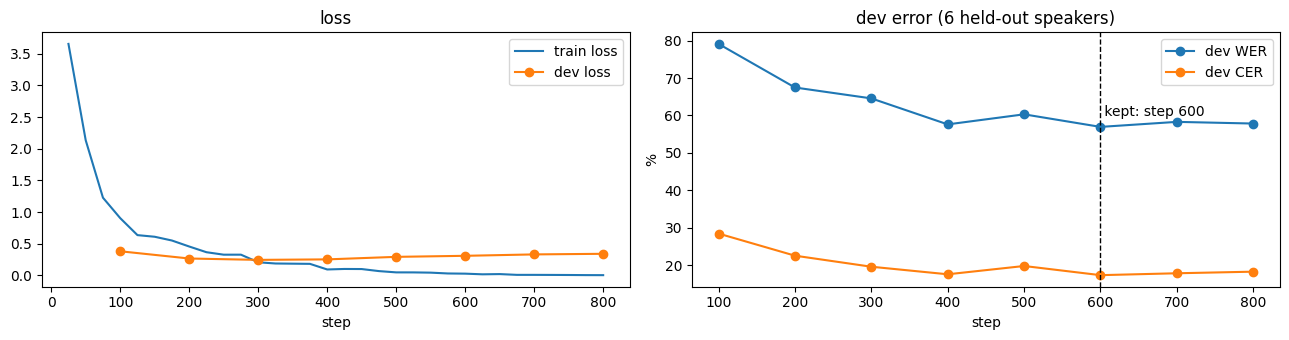

,step,eval_loss,eval_wer,eval_cer
0,100,0.38,79.15,28.42
1,200,0.27,67.49,22.51
2,300,0.24,64.57,19.56
3,400,0.25,57.62,17.53
4,500,0.29,60.31,19.75
5,600,0.31,56.95,17.30
6,700,0.33,58.30,17.81
7,800,0.34,57.85,18.23


In [9]:
log = json.load(open(f"{NEW}/task2/ft_small/train_log.json"))
tr = pd.DataFrame([r for r in log if "loss" in r and "eval_loss" not in r])
ev = pd.DataFrame([r for r in log if "eval_wer" in r])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].plot(tr.step, tr.loss, label="train loss"); ax[0].plot(ev.step, ev.eval_loss, "o-", label="dev loss")
ax[0].set_xlabel("step"); ax[0].set_title("loss"); ax[0].legend()
ax[1].plot(ev.step, ev.eval_wer, "o-", label="dev WER"); ax[1].plot(ev.step, ev.eval_cer, "o-", label="dev CER")
best = ev.loc[ev.eval_wer.idxmin()]
ax[1].axvline(best.step, color="k", ls="--", lw=1); ax[1].text(best.step, best.eval_wer + 3, f" kept: step {int(best.step)}")
ax[1].set_xlabel("step"); ax[1].set_ylabel("%"); ax[1].set_title("dev error (6 held-out speakers)"); ax[1].legend()
plt.tight_layout(); plt.show()
display(ev[["step", "eval_loss", "eval_wer", "eval_cer"]].round(2))

Baseline vs fine-tuned on the OpenSLR test:

  "over_long_output_%": 1.0,
  "seconds": 48.0,
  "device": "Tesla T4"
}
✓  whisper-small FINE-TUNED WER (OpenSLR test): submitted 66.36 | reproduced 66.61
✓  whisper-small FINE-TUNED CER: submitted 21.44 | reproduced 21.48


,zero-shot whisper-small,fine-tuned
WER %,144.05,66.61
CER %,135.67,21.48


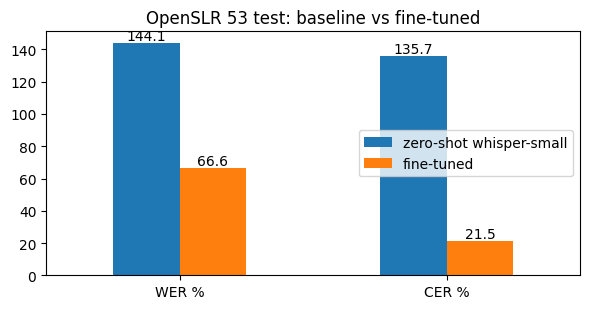

   "অজি গর",
   2.0
  ],
  [
   "এসময় রিজভী আহমেদের",
   "এ সময় রিসবি আহম্মে দের",
   1.6666666666666667
  ],
  [
   "এফআইআরে উল্লেখ",
   "এফায় আরে উল্লেক",
   1.5
  ],
  [
   "জাফলং সিলেট",
   "চাপ লঙ্ক শিলেড",
   1.5
  ],
  [
   "ভারতনাট্যম ডাউনলোড",
   "ভারত নাট্টম ডাউলোর",
   1.5
  ],
  [
   "টেলিভিশন চ্যানেল",
   "টেলী বিশন চেয়ানের",
   1.5
  ]
 ]
}


,"fine-tuned, test"
first_word_deleted_%,0.0
middle_word_deleted_%,6.5
last_word_deleted_%,9.0
inserted_words_per_100_ref_words,6.0


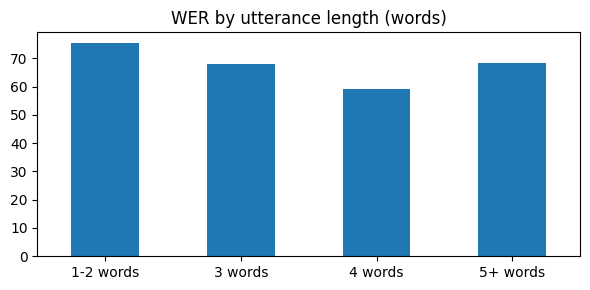

,reference,output,count
0,কেন,কেনো,2
1,চীনাওয়াত,চিনাওয়াত,2
2,নৌকায়,নকায়,1
3,সাঁকো,শাকবেদে,1
4,আত্মরক্ষার,প্রয়েজন,1
5,প্রয়োজনটাই,টাই,1
6,পুরস্কার,পুরশকার,1
7,সম্মাননায়,ননায়,1
8,এক,একটুক্র,1
9,টুকরো,চামরা,1


In [10]:
sh(f"{EVAL} task2_asr/evaluate_asr.py --model {FT_WHISPER} --run ft_small_test", tail=4)
s, n = (json.load(open(f"{r}/task2/ft_small_test/metrics.json")) for r in (SUB, NEW))
tol = 3 if RUN_WHISPER_FINETUNE else 0.3
check("whisper-small FINE-TUNED WER (OpenSLR test)", s["WER%"], n["WER%"], tol=tol)
check("whisper-small FINE-TUNED CER", s["CER%"], n["CER%"], tol=tol)
b = json.load(open(f"{NEW}/task2/baseline_small/metrics.json"))
res = pd.DataFrame({"zero-shot whisper-small": [b["WER%"], b["CER%"]], "fine-tuned": [n["WER%"], n["CER%"]]}, index=["WER %", "CER %"])
display(res)
ax = res.plot.bar(rot=0, figsize=(6, 3.2), title="OpenSLR 53 test: baseline vs fine-tuned")
for c in ax.containers: ax.bar_label(c, fmt="%.1f")
plt.tight_layout(); plt.show()

sh(f"{EVAL} task2_asr/analyze_asr_errors.py --run ft_small_test", tail=30)
ea = json.load(open(f"{NEW}/task2/ft_small_test/error_analysis.json", encoding="utf-8"))
display(pd.Series({k: ea[k] for k in ["first_word_deleted_%", "middle_word_deleted_%", "last_word_deleted_%",
                                      "inserted_words_per_100_ref_words"]}, name="fine-tuned, test").to_frame())
pd.Series(ea["WER%_by_utterance_length"]).plot.bar(rot=0, figsize=(6, 3), title="WER by utterance length (words)")
plt.tight_layout(); plt.show()
display(pd.DataFrame(ea["top_substitutions(ref -> hyp, count)"][:10], columns=["reference", "output", "count"]))

## 4. Errors on real speech: my consultations A and B

Lines are cut with my hand-checked timestamps and tagged SHORT, EN (English words), MED, OVERLAP.
- end words lost: the 128-token limit (~2 tokens per Bengali character)
- short replies: না → নাম, জি → চি
- code-switching: ভাইরাল ফিভার
- medical terms: প্যারাসিটামল
- hallucination on silence
- noise: white noise at 20 / 10 / 5 dB

=== ft_consult (pad 0.0s) : WER% / CER% / lines ===
  ALL         82.0   41.6  46
  SHORT       85.2   49.2  15
  EN          73.5   37.2  11
  MED         81.6   39.5  12
  OVERLAP     83.3   35.3   4
  untagged    87.8   43.6  15


,WER %,CER %,lines
ALL,82.0,41.6,46.0
SHORT,85.2,49.2,15.0
EN,73.5,37.2,11.0
MED,81.6,39.5,12.0
OVERLAP,83.3,35.3,4.0
untagged,87.8,43.6,15.0


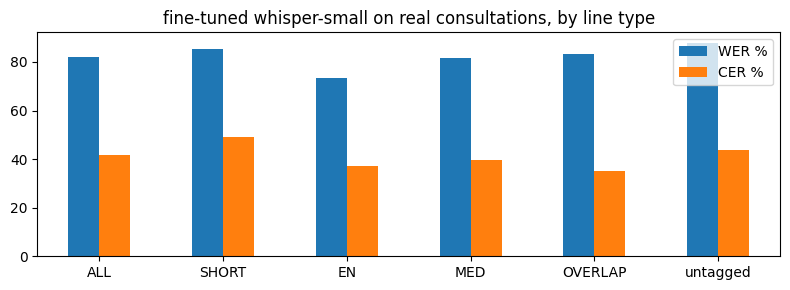

**SHORT** (worst lines)

,line,ref,hyp,cer
20,A20,আচ্ছা,আদ সাম্পিক,1.600000
5,A6,হ্যাঁ একটু কাশি আছে আর মাথাটা খুব ব্যথা করে,হ্যাসি আছে যেয়া নাথাটে পু্ভাথা কলে,0.558140
7,A8,না এখনো খাইনি শুধু গরম পানি খাচ্ছি আর,নায়ানও খায়িনি সুধো গাড়ানপানি খাছেন,0.540541
35,B8,হুম প্রস্রাব ঠিকমতো হচ্ছে,পর্সাব খিক্মত ওছে,0.520000


**EN** (worst lines)

,line,ref,hyp,cer
21,A21,জ্বরের জন্য প্যারাসিটামল ফাইভ হান্ড্রেড মিলিগ্...,জড়ের জন্য পেরাসি তেমল ফাইডেট মিলিগ্রাম তিনে ত...,0.533333
39,B12,ঠিক আছে ওর একটু ডিহাইড্রেশন হয়েছে প্রতিবার পা...,ঠিকাছে অরিটু ডিহায়ে দেশন হচেপ্রতিবার পায়খানা...,0.423529
11,A12,প্রেশার একটু হাই থাকে আমি অ্যামলোডিপিন ফাইভ মি...,প্রেশারিত হায় থাকেলে আভি এম্ডাড়িপিন ফাইর নিল...,0.421053
10,A11,আপনার কি ডায়াবেটিস বা হাই ব্লাড প্রেশার আছে,আপ্নিকি ডায়াপেটিক বাওয়া হাই ভালাক প্রশও রাছে,0.409091


**MED** (worst lines)

,line,ref,hyp,cer
21,A21,জ্বরের জন্য প্যারাসিটামল ফাইভ হান্ড্রেড মিলিগ্...,জড়ের জন্য পেরাসি তেমল ফাইডেট মিলিগ্রাম তিনে ত...,0.533333
38,B11,ফার্মেসি থেকে একটা সিরাপ দিয়েছিল মেট্রোনিডাজল...,ফার্মসিকেকে একত চিরাফদেই ছেলো ম্যাক্ঠনি ডাজয় ...,0.481481
39,B12,ঠিক আছে ওর একটু ডিহাইড্রেশন হয়েছে প্রতিবার পা...,ঠিকাছে অরিটু ডিহায়ে দেশন হচেপ্রতিবার পায়খানা...,0.423529
11,A12,প্রেশার একটু হাই থাকে আমি অ্যামলোডিপিন ফাইভ মি...,প্রেশারিত হায় থাকেলে আভি এম্ডাড়িপিন ফাইর নিল...,0.421053


**Cut-off endings** (output ends in a broken character with 128 tokens)

,line,ref,hyp
21,A21,জ্বরের জন্য প্যারাসিটামল ফাইভ হান্ড্রেড মিলিগ্...,জড়ের জন্য পেরাসি তেমল ফাইডেট মিলিগ্রাম তিনে ত...
25,A25,পেটে ব্যথা রক্তপাত বা খুব দুর্বল লাগে সাথে সাথ...,পেটে বেথা বা রক্তপার্দ বা খুপ দুরবল লাগে সাথে ...
39,B12,ঠিক আছে ওর একটু ডিহাইড্রেশন হয়েছে প্রতিবার পা...,ঠিকাছে অরিটু ডিহায়ে দেশন হচেপ্রতিবার পায়খানা...


In [11]:
sh(f"{EVAL} task2_asr/eval_consult.py --model {FT_WHISPER} --run ft_consult", tail=7)
display(Audio(f"{REPO}/data/consultation/audio/consult_A.wav"))
by_tag = pd.DataFrame(json.load(open(f"{NEW}/task2/ft_consult/summary.json", encoding="utf-8"))["WER%,CER%,lines"],
                      index=["WER %", "CER %", "lines"]).T
display(by_tag)
by_tag[["WER %", "CER %"]].plot.bar(rot=0, figsize=(8, 3), title="fine-tuned whisper-small on real consultations, by line type")
plt.tight_layout(); plt.show()
lines = pd.read_csv(f"{NEW}/task2/ft_consult/lines.csv")
for tag in ["SHORT", "EN", "MED"]:
    display(Markdown(f"**{tag}** (worst lines)"))
    display(lines[lines.tags.fillna("").str.contains(tag)].sort_values("cer", ascending=False)[["line", "ref", "hyp", "cer"]].head(4))
display(Markdown("**Cut-off endings** (output ends in a broken character with 128 tokens)"))
display(lines[lines.hyp.fillna("").str.contains("�")][["line", "ref", "hyp"]])

In [12]:
sh(f"{EVAL} task2_asr/hallucination_probe.py --model {FT_WHISPER}", tail=6)       # no gate vs VAD gate
s, n = (json.load(open(f"{r}/task2/hallucination_probe/report.json", encoding="utf-8")) for r in (SUB, NEW))
for g in ["no_gate", "with_vad_gate"]:
    check(f"non-speech clips that produce text, {g} (of {n[g]['probes']})", s[g]["probes_with_text"], n[g]["probes_with_text"], tol=1)
display(pd.DataFrame({g: {k: n[g][k] for k in ["probes", "probes_with_text", "invented_words"]} for g in ["no_gate", "with_vad_gate"]}))
display(Markdown("**Hallucination examples** (text produced for pauses with no speech, no gate)"))
display(pd.DataFrame(n["no_gate"]["examples"], columns=["pause", "invented output"]))
for snr in [20, 10, 5]:
    sh(f"{EVAL} task2_asr/eval_consult.py --model {FT_WHISPER} --max_new_tokens 440 --noise_snr {snr} --run ft_consult_tok440_noise{snr}db", tail=6)

  "probes": 19,
  "probes_with_text": 0,
  "invented_words": 0,
  "examples": []
 }
}
✓  non-speech clips that produce text, no_gate (of 19): submitted 19 | reproduced 19
✓  non-speech clips that produce text, with_vad_gate (of 19): submitted 0 | reproduced 0


,no_gate,with_vad_gate
probes,19,19
probes_with_text,19,0
invented_words,49,0


**Hallucination examples** (text produced for pauses with no speech, no gate)

,pause,invented output
0,consult_A gap 0.1-1.1s,ক্যাসায়াসায় ক্যায়ায়
1,consult_A gap 6.7-7.2s,ক্যাসায়াসায় ক্যায়ায়
2,consult_A gap 11.0-11.5s,ক্যাসায়াসায়ায় ক্যাসায়ায়
3,consult_A gap 21.6-22.1s,ক্যাসায়াসায় ক্যায়ায়
4,consult_A gap 23.8-24.3s,ক্যাসায়াসায় ক্যায়ায়
5,consult_A gap 30.9-31.3s,ক্যাসায়াসায় ক্যায়ায়ায়


  ALL         82.0   43.8  46
  SHORT       85.2   54.6  15
  EN          71.6   34.0  11
  MED         81.6   38.5  12
  OVERLAP     83.3   41.2   4
  untagged    88.9   49.0  15
  ALL         89.3   54.6  46
  SHORT       90.7   62.1  15
  EN          80.4   47.3  11
  MED         89.8   52.3  12
  OVERLAP     83.3   47.1   4
  untagged    96.7   57.6  15
  ALL         94.1   61.6  46
  SHORT       98.1   72.5  15
  EN          87.3   54.0  11
  MED         91.8   57.1  12
  OVERLAP    100.0   67.6   4
  untagged    98.9   64.6  15


## 5. Fixes, one at a time

- token budget 128 → 440: no more cut-off lines
- Silero VAD gate: clips with no speech are not transcribed, so nothing is invented

=== ft_consult_tok440 (pad 0.0s) : WER% / CER% / lines ===
  ALL         80.9   39.2  46
  SHORT       85.2   49.2  15
  EN          70.6   31.3  11
  MED         79.6   35.0  12
  OVERLAP     83.3   35.3   4
  untagged    87.8   43.2  15
=== ft_consult_tok440_vadgate (pad 0.0s) : WER% / CER% / lines ===
  ALL         80.9   39.2  46
  SHORT       85.2   49.2  15
  EN          70.6   31.3  11
  MED         79.6   35.0  12
  OVERLAP     83.3   35.3   4
  untagged    87.8   43.2  15
✓  consult CER, ft_consult: submitted 41.6 | reproduced 41.6
✓  consult CER, ft_consult_tok440: submitted 39.2 | reproduced 39.2
✓  consult CER, ft_consult_tok440_vadgate: submitted 39.2 | reproduced 39.2
✓  consult CER, ft_consult_tok440_noise20db: submitted 44.0 | reproduced 43.8
✓  consult CER, ft_consult_tok440_noise10db: submitted 54.4 | reproduced 54.6
✓  consult CER, ft_consult_tok440_noise5db: submitted 61.6 | reproduced 61.6


,run,submitted CER,reproduced CER
0,ft_consult,41.6,41.6
1,ft_consult_tok440,39.2,39.2
2,ft_consult_tok440_vadgate,39.2,39.2
3,ft_consult_tok440_noise20db,44.0,43.8
4,ft_consult_tok440_noise10db,54.4,54.6
5,ft_consult_tok440_noise5db,61.6,61.6


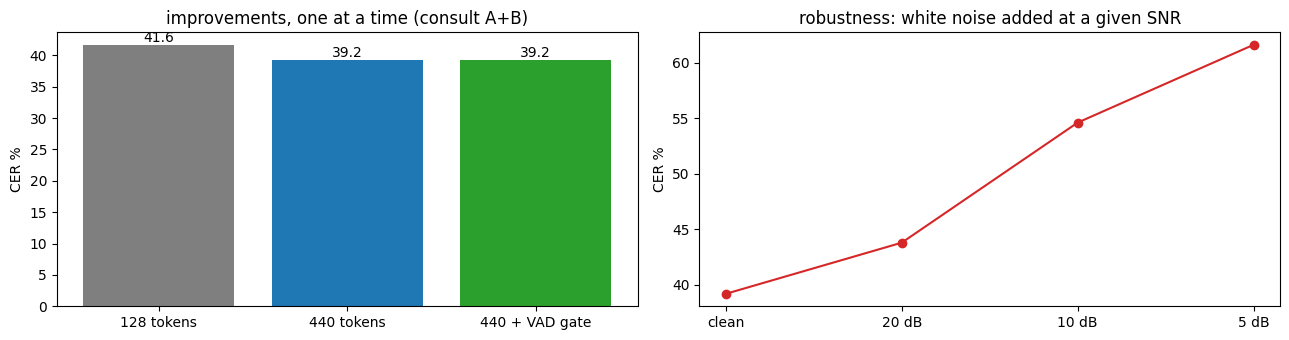

In [13]:
sh(f"{EVAL} task2_asr/eval_consult.py --model {FT_WHISPER} --max_new_tokens 440 --run ft_consult_tok440", tail=7)
sh(f"{EVAL} task2_asr/eval_consult.py --model {FT_WHISPER} --max_new_tokens 440 --vad_gate --run ft_consult_tok440_vadgate", tail=7)
def consult_cer(root, run):
    return json.load(open(f"{root}/task2/{run}/summary.json", encoding="utf-8"))["WER%,CER%,lines"]["ALL"][1]
rows = []
for run in ["ft_consult", "ft_consult_tok440", "ft_consult_tok440_vadgate",
            "ft_consult_tok440_noise20db", "ft_consult_tok440_noise10db", "ft_consult_tok440_noise5db"]:
    check(f"consult CER, {run}", consult_cer(SUB, run), consult_cer(NEW, run), tol=3)
    rows.append({"run": run, "submitted CER": consult_cer(SUB, run), "reproduced CER": consult_cer(NEW, run)})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
steps = {"128 tokens": "ft_consult", "440 tokens": "ft_consult_tok440", "440 + VAD gate": "ft_consult_tok440_vadgate"}
v = [consult_cer(NEW, r) for r in steps.values()]
ax[0].bar(list(steps), v, color=["C7", "C0", "C2"]); ax[0].bar_label(ax[0].containers[0], fmt="%.1f")
ax[0].set_ylabel("CER %"); ax[0].set_title("improvements, one at a time (consult A+B)")
snr = {"clean": "ft_consult_tok440", "20 dB": "ft_consult_tok440_noise20db", "10 dB": "ft_consult_tok440_noise10db", "5 dB": "ft_consult_tok440_noise5db"}
ax[1].plot(list(snr), [consult_cer(NEW, r) for r in snr.values()], "o-", color="C3")
ax[1].set_ylabel("CER %"); ax[1].set_title("robustness: white noise added at a given SNR")
plt.tight_layout(); plt.show()

## 6. Model selection

Rule fixed in advance: lowest CER on my real consultations. tugstugi whisper-medium repeats most OpenSLR test
sentences word for word (it was trained on them), so only the consultations are a fair test.

In [14]:
IC = f"{DATA}/models/indic-conformer-600m"   # a plain folder: the ONNX weights refuse the HF cache's symlinks
if not os.path.exists(f"{IC}/model_onnx.py"):
    sh(f"{EVAL} -c \"import os; from huggingface_hub import snapshot_download as d; "
       f"d('ai4bharat/indic-conformer-600m-multilingual', local_dir='{IC}', token=os.environ['HF_TOKEN'])\"", tail=1)
print("IndicConformer 600M ready:", IC)

Fetching 404 files: 100%|██████████| 404/404 [00:32<00:00, 12.53it/s]
IndicConformer 600M ready: /content/aimscribe_data/models/indic-conformer-600m


  "seconds": 59.0,
  "device": "Tesla T4"
}
✓  tugstugi: % of OpenSLR test sentences reproduced verbatim: submitted 88.2 | reproduced 87.9
=== zs_tugstugi_medium_consult (pad 0.0s) : WER% / CER% / lines ===
  ALL         27.2   13.0  46
  SHORT       27.8   16.2  15
  EN          24.5    9.4  11
  MED         25.5   10.8  12
  OVERLAP     66.7   23.5   4
  untagged    30.0   15.6  15
=== zs_indicconformer600m_consult (pad 0.0s) : WER% / CER% / lines ===
  ALL         18.8    7.2  46
  SHORT       31.5   14.6  15
  EN          18.6    6.1  11
  MED         21.4    6.6  12
  OVERLAP     50.0   17.6   4
  untagged    10.0    4.9  15
✓  consult CER, my whisper-small fine-tune: submitted 39.2 | reproduced 39.2
✓  consult CER, tugstugi whisper-medium: submitted 13.0 | reproduced 13.0
✓  consult CER, IndicConformer 600M (RNN-T): submitted 7.2 | reproduced 7.2


,consult CER (reproduced)
model,
my whisper-small fine-tune,39.2
tugstugi whisper-medium,13.0
IndicConformer 600M (RNN-T),7.2


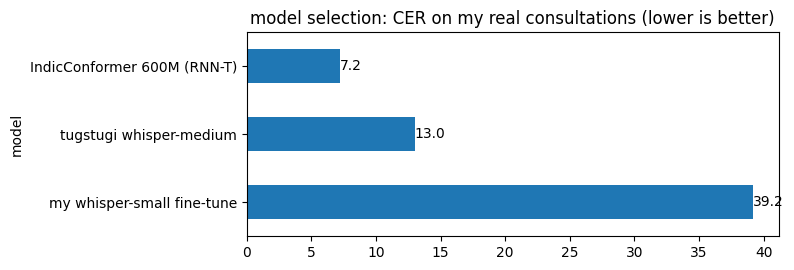

**IndicConformer 600M: line by line** (reference vs output)

,line,role,tags,ref,hyp,cer
0,A1,Doctor,NaN,আসসালামু আলাইকুম বসুন বলুন আপনার কী সমস্যা হচ্ছে,আসসালামু আলাইকুম বসুন বলুন আপনার কি সমস্যা হচ্ছে,0.02
1,A2,Patient,NaN,ওয়ালাইকুম আসসালাম ডাক্তার সাহেব আমার তিন দিন ...,ওয়ালাইকুম আসসালাম ডাক্তার সাহেব আমার তিন দিন ...,0.06
2,A3,Doctor,NaN,জ্বর কত ছিল মেপেছিলেন,জ্বর কত ছিল মেপেছিলেন,0.00
3,A4,Patient,SHORT,জি কাল রাতে একশো দুই ছিল,জি গতকালকে একশো দুই ছিল,0.25
4,A5,Doctor,SHORT,হুম সাথে কাশি বা গলা ব্যথা আছে,হম সাথে কাশি অথবা গলা ব্যথা আছে,0.10
5,A6,Patient,SHORT,হ্যাঁ একটু কাশি আছে আর মাথাটা খুব ব্যথা করে,হ্যাঁ একটু কাশি আছে আর মাথা টেপর ব্যথা করো,0.16
6,A7,Doctor,NaN,কোনো ওষুধ খেয়েছেন,কোনো ওষুধ খেয়েছেন,0.00
7,A8,Patient,SHORT,না এখনো খাইনি শুধু গরম পানি খাচ্ছি আর,না এখনও খায়নি শুধু গরম পানি খাচ্ছেন,0.19
8,A9,Doctor,"OVERLAP,MED",প্যারাসিটামলও খাননি,প্যারাসিটামল ওখানে নেই,0.32
9,A10,Patient,SHORT,না,না,0.00


In [16]:
sh(f"{EVAL} task2_asr/evaluate_asr.py --model bengaliAI/tugstugi_bengaliai-asr_whisper-medium --max_new_tokens 440 --run zs_tugstugi_medium", tail=3)
p = pd.read_csv(f"{NEW}/task2/zs_tugstugi_medium/predictions.csv")
ps = pd.read_csv(f"{SUB}/task2/zs_tugstugi_medium/predictions.csv")
check("tugstugi: % of OpenSLR test sentences reproduced verbatim", round(100 * (ps.ref_norm == ps.pred_norm).mean(), 1),
      round(100 * (p.ref_norm == p.pred_norm).mean(), 1), tol=2)
sh(f"{EVAL} task2_asr/eval_consult.py --model bengaliAI/tugstugi_bengaliai-asr_whisper-medium --max_new_tokens 440 --run zs_tugstugi_medium_consult", tail=7)
sh(f"{EVAL} task2_asr/eval_consult.py --backend indicconformer --model {IC} --run zs_indicconformer600m_consult", tail=7)
rows = []
for run, name in [("ft_consult_tok440", "my whisper-small fine-tune"), ("zs_tugstugi_medium_consult", "tugstugi whisper-medium"),
                  ("zs_indicconformer600m_consult", "IndicConformer 600M (RNN-T)")]:
    check(f"consult CER, {name}", consult_cer(SUB, run), consult_cer(NEW, run), tol=0.3 if "Indic" in name else 1)
    rows.append({"model": name, "consult CER (reproduced)": consult_cer(NEW, run)})
sel = pd.DataFrame(rows).set_index("model")
display(sel)
ax = sel.plot.barh(legend=False, figsize=(8, 2.8), title="model selection: CER on my real consultations (lower is better)")
ax.bar_label(ax.containers[0], fmt="%.1f"); plt.tight_layout(); plt.show()
best = pd.read_csv(f"{NEW}/task2/zs_indicconformer600m_consult/lines.csv")
display(Markdown("**IndicConformer 600M: line by line** (reference vs output)"))
display(best[["line", "role", "tags", "ref", "hyp", "cer"]].round(2))

## 7. Clinical test: 100 sentences × 6 synthetic voices

Made with Indic Parler-TTS; the audio is in the repo. Term accuracy = share of drug, dose and test names found in
the output.

 "term_acc_unseen%": 67.1,
 "terms_unseen": 222
}
 "term_acc_unseen%": 50.9,
 "terms_unseen": 222
}
✓  clinical test CER, tts_sent_indicconformer: submitted 2.6 | reproduced 2.6
✓  clinical test drug/test-name accuracy, tts_sent_indicconformer: submitted 71.1 | reproduced 71.1
✓  clinical test CER, tts_sent_tugstugi: submitted 3.7 | reproduced 3.7
✓  clinical test drug/test-name accuracy, tts_sent_tugstugi: submitted 57.9 | reproduced 57.9


,model,CER,MED CER,term acc,seen terms,unseen terms
0,tts_sent_indicconformer,2.6,3.1,71.1,63.6,67.1
1,tts_sent_tugstugi,3.7,5.1,57.9,56.1,50.9


most missed terms (600M): {'সালবিউটামল': 10, 'সেফিক্সিম': 6, 'মেটফরমিন': 6, 'ইসোমিপ্রাজল': 6, 'মন্টিলুকাস্ট': 6, 'ডমপেরিডন': 6, 'অ্যাটোরভাস্টাটিন': 6, 'টুয়েন্টি': 6, 'মক্সিফ্লক্সাসিন': 6, 'এইচবিএওয়ানসি': 6, 'ফলোআপ': 6, 'অ্যামোক্সিসিলিন': 5, 'সিপ্রোফ্লক্সাসিন': 5, 'ফ্লুকোনাজল': 5, 'এক্সরে': 5}


,WER%,CER%,term_acc%,term_acc_ignoring_spaces%,clips
Aditi,14.2,3.0,68.4,73.7,100.0
Arjun,12.3,2.6,71.6,78.9,100.0
Arnav,9.7,1.8,74.7,82.1,100.0
Rashmi,9.1,1.6,76.8,85.3,100.0
Riya,14.1,4.3,64.2,68.4,100.0
Tapan,10.0,2.1,70.5,77.9,100.0


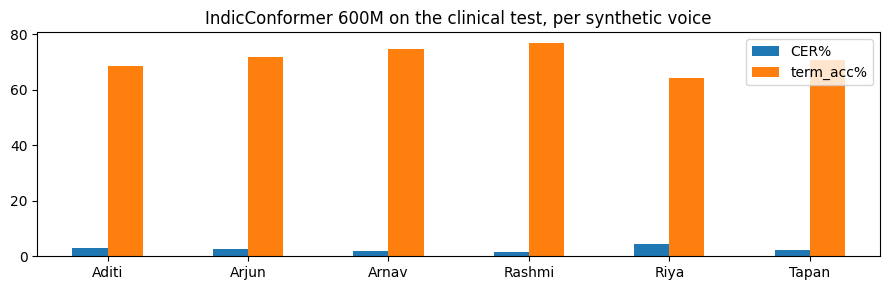

In [17]:
os.makedirs(f"{DATA}/tts_sentences", exist_ok=True)
for f in Path(f"{REPO}/data/tts/audio").glob("*.wav"):
    if not os.path.exists(f"{DATA}/tts_sentences/{f.name}"):
        shutil.copy(f, f"{DATA}/tts_sentences/")
sh(f"{EVAL} task2_asr/eval_tts_sentences.py --backend indicconformer --model {IC} --run tts_sent_indicconformer", tail=3)
sh(f"{EVAL} task2_asr/eval_tts_sentences.py --backend whisper --model bengaliAI/tugstugi_bengaliai-asr_whisper-medium --run tts_sent_tugstugi", tail=3)
def tts(root, run):
    return json.load(open(f"{root}/task2/{run}/summary.json", encoding="utf-8"))
rows = []
for run in ["tts_sent_indicconformer", "tts_sent_tugstugi"]:
    s, n = tts(SUB, run), tts(NEW, run)
    check(f"clinical test CER, {run}", s["ALL"]["CER%"], n["ALL"]["CER%"], tol=0.3)
    check(f"clinical test drug/test-name accuracy, {run}", s["ALL"]["term_acc%"], n["ALL"]["term_acc%"], tol=1)
    rows.append({"model": run, "CER": n["ALL"]["CER%"], "MED CER": n["MED"]["CER%"], "term acc": n["ALL"]["term_acc%"],
                 "seen terms": n.get("term_acc_seen_in_training%"), "unseen terms": n.get("term_acc_unseen%")})
display(pd.DataFrame(rows))
print("most missed terms (600M):", tts(NEW, "tts_sent_indicconformer")["most_missed_terms"])
byv = pd.DataFrame(tts(NEW, "tts_sent_indicconformer")["by_voice"]).T
display(byv)
ax = byv[["CER%", "term_acc%"]].plot.bar(rot=0, figsize=(9, 3), title="IndicConformer 600M on the clinical test, per synthetic voice")
plt.tight_layout(); plt.show()
display(Audio(sorted(Path(f"{DATA}/tts_sentences").glob("*.wav"))[0]))

## 8. Clinical fine-tune of IndicConformer 120M

The 600M is ONNX and can't be trained; the 120M `.nemo` can (AI4Bharat NeMo fork, Python 3.10).

- 1,500 template sentences, voiced by IndicF5 with 64 real OpenSLR voices; no test sentence in them
- test drug names split into seen / unseen in training
- QC drops clips with CER > 50 % → 1,012 clips, mixed 1:1 with real speech
- CTC branch only, 1,500 steps, lr 5e-5, best dev WER kept
- rule set before training: replace the 600M only if consult CER ≤ 7.2 (got 9.4, so the 600M stays)

By default the submitted model is downloaded and evaluated.

In [18]:
NEMO_ENV = dict(os.environ, NUMBA_CUDA_DRIVER="/usr/lib64-nvidia/libcuda.so", CUDA_HOME="/usr/local/cuda")
B120 = f"{DATA}/models/indicconformer-bn-120m/indicconformer_stt_bn_hybrid_rnnt_large.nemo"
if RUN_120M or RUN_CLINICAL_FINETUNE:
    sh("uv python install 3.10", tail=1)
    NEMO = venv("venv_nemo", "3.10")
    if not os.path.exists("/content/NeMo-ai4b"):
        sh(f"uv pip install -q --python {NEMO} torch==2.1.2 torchaudio==2.1.2 --index-url https://download.pytorch.org/whl/cu121")
        sh("git clone -q --depth 1 -b nemo-v2 https://github.com/AI4Bharat/NeMo.git /content/NeMo-ai4b")
        sh(f'cd /content/NeMo-ai4b && uv pip install -q --python {NEMO} Cython packaging "numpy<2" && uv pip install -q --python {NEMO} -e ".[asr]"', tail=2)
        sh(f"uv pip install -q --python {NEMO} -r envs/requirements-nemo.txt", tail=2)
    sh(f"{NEMO} -c \"import os; from huggingface_hub import hf_hub_download as d; d('ai4bharat/indicconformer_stt_bn_hybrid_ctc_rnnt_large', "
       f"'indicconformer_stt_bn_hybrid_rnnt_large.nemo', local_dir='{os.path.dirname(B120)}', token=os.environ['HF_TOKEN'])\"", tail=1)
    def nemo(cmd, tail=8):
        p = subprocess.run(f"{NEMO} {cmd}", shell=True, cwd=REPO, env=NEMO_ENV, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
        print("\n".join([l for l in p.stdout.splitlines() if not re.search(r"NeMo W|[Ww]arning", l)][-tail:]))
        if p.returncode: raise RuntimeError(cmd)
if RUN_120M:
    for dec in ["rnnt", "ctc"]:
        nemo(f"task2_asr/eval_consult.py --backend indicconformer_nemo --decoding {dec} --model {B120} --run zs_indicconformer120m_{dec}_consult", tail=7)
        check(f"consult CER, 120M zero-shot {dec}", consult_cer(SUB, f"zs_indicconformer120m_{dec}_consult"),
              consult_cer(NEW, f"zs_indicconformer120m_{dec}_consult"), tol=0.3)
    nemo(f"task2_asr/eval_tts_sentences.py --backend indicconformer_nemo --decoding ctc --model {B120} --run tts_sent_ic120m_zs_ctc", tail=3)
    check("clinical test term accuracy, 120M zero-shot (CTC)", tts(SUB, "tts_sent_ic120m_zs_ctc")["ALL"]["term_acc%"],
          tts(NEW, "tts_sent_ic120m_zs_ctc")["ALL"]["term_acc%"], tol=1)

 + cpython-3.10.22-linux-x86_64-gnu (python3.10)






=== zs_indicconformer120m_rnnt_consult (pad 0.0s) : WER% / CER% / lines ===
  ALL         23.9    9.1  46
  SHORT       25.9   11.2  15
  EN          30.4   10.1  11
  MED         31.6    9.9  12
  OVERLAP     33.3    5.9   4
  untagged    15.6    7.4  15
✓  consult CER, 120M zero-shot rnnt: submitted 9.1 | reproduced 9.1
=== zs_indicconformer120m_ctc_consult (pad 0.0s) : WER% / CER% / lines ===
  ALL         28.3   11.1  46
  SHORT       27.8   12.9  15
  EN          36.3   12.1  11
  MED         39.8   12.9  12
  OVERLAP     66.7   23.5   4
  untagged    17.8    8.4  15
✓  consult CER, 120M zero-shot ctc: submitted 11.1 | reproduced 11.1
 "term_acc_unseen%": 44.1,
 "terms_unseen": 222
}
✓  clinical test term accuracy, 120M zero-shot (CTC): submitted 51.6 | reproduced 51.6


Training data and QC:

1500 sentences | roles: {'D': 821, 'P': 387, 'A': 292} | 64 cloned voices


,id,role,text,ref_speaker
0,S00000,P,আমি আগে সেটিরিজিন খেয়েছিলাম,71522
1,S00001,D,আজকেই একটা পিটি আইএনআর করা দরকার,13b6a
2,S00002,A,ওর কয়েক মাস ধরে বমি,66c6b
3,S00003,D,মনে হচ্ছে থাইরয়েড হয়েছে,7d004
4,S00004,P,ইকোকার্ডিওগ্রাম কি করাতে হবে,2d98b
5,S00005,D,কোমরে ব্যথা কতদিন ধরে হচ্ছে,d9b11
6,S00006,P,ইউরিক অ্যাসিড কি করাতে হবে,58998
7,S00007,D,টারবিনাফিন এর সাথে রাবেপ্রাজল যোগ করছি,3ccf1


,count,examples
seen_in_training,40,"অ্যাজিথ্রোমাইসিন, অ্যাটোরভাস্টাটিন, অ্যাসপিরিন..."
unseen,39,"অস্টিওআর্থ্রাইটিস, অ্যাজমা, অ্যান্টিবায়োটিক, ..."
dev_terms_excluded,19,"প্যারাসিটামল, অ্যামলোডিপিন, সিবিসি, ডেঙ্গু, এন..."


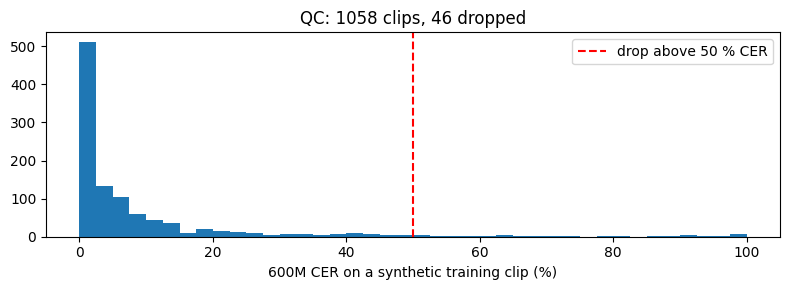

**Dropped clips (worst)**: what IndicF5 failures look like

,id,ref,hyp,cer
854,S00858,ওর দুই সপ্তাহ ধরে মাথা ব্যথা,প্রীতি মাথর ও দুইটা সপ্তাহ মাথাব্যাথা প্রকৃন্থি,1.0
1034,S01040,ক্লোট্রিমাজল ওয়ান ফিফটি আট ঘণ্টা পরপর খাবেন,NaN,1.0
1043,S01051,লেভোফ্লক্সাসিন দিনে একবার খাওয়ার পরে ছয় মাস ...,NaN,1.0
14,S00014,জি খেয়েছি,আ,1.0
587,S00590,জি খেয়েছি,হম,1.0


,120M training settings
inspect,False
run,icft_120m
max_steps,1500
lr,0.00005
batch,8
real_ratio,1.0
val_every,250
train_clips,2024
tts_clips,1012
best_ckpt,/content/aimscribe/results/task2/icft_120m/ckp...


In [19]:
sent = pd.read_csv(f"{REPO}/data/tts_train/train_sentences.tsv", sep="\t")
print(f"{len(sent)} sentences | roles: {sent.role.value_counts().to_dict()} | {sent.ref_speaker.nunique()} cloned voices")
display(sent[["id", "role", "text", "ref_speaker"]].head(8))
terms = json.load(open(f"{REPO}/data/tts_train/split_terms.json", encoding="utf-8"))
display(pd.DataFrame({k: [len(v), ", ".join(v[:6]) + " …"] for k, v in terms.items()}, index=["count", "examples"]).T)
qc = pd.read_csv(f"{REPO}/data/tts_train/qc_600m.csv")
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(qc.cer.clip(upper=1.5) * 100, bins=40); ax.axvline(50, color="r", ls="--", label="drop above 50 % CER")
ax.set_xlabel("600M CER on a synthetic training clip (%)"); ax.set_title(f"QC: {len(qc)} clips, {(qc.cer > 0.5).sum()} dropped")
ax.legend(); plt.tight_layout(); plt.show()
display(Markdown("**Dropped clips (worst)**: what IndicF5 failures look like"))
display(qc.sort_values("cer", ascending=False).head(5))
display(pd.Series(json.load(open(f"{NEW}/task2/icft_120m/train_config.json")), name="120M training settings").to_frame())

Re-training (only with `RUN_CLINICAL_FINETUNE = True`, ~4 h):

In [20]:
if RUN_CLINICAL_FINETUNE:
    F5 = venv("venv_f5")
    if not os.path.exists("/content/venv_f5/.ready"):
        sh(f"uv pip install -q --python {F5} torch==2.5.1 torchaudio==2.5.1 --index-url https://download.pytorch.org/whl/cu121")
        sh(f'uv pip install -q --python {F5} "git+https://github.com/ai4bharat/IndicF5.git" librosa soundfile pandas')
        sh(f'uv pip install -q --python {F5} pyarrow==17.0.0 datasets==3.1.0 transformers==4.49.0 "accelerate<1.5"')
        Path("/content/venv_f5/.ready").touch()
    shutil.copytree(f"{REPO}/data/tts_train", "/content/submitted_data/tts_train", dirs_exist_ok=True)
    sh(f"{F5} data/make_tts_train.py --n 1500", tail=4)
    for f in ["train_sentences.tsv", "split_terms.json"]:
        print(f, "identical to submitted:", filecmp.cmp(f"/content/submitted_data/tts_train/{f}", f"{REPO}/data/tts_train/{f}", shallow=False))
    sh(f"{F5} data/make_tts_train.py --n 1500 --synth --only_ids /content/submitted_data/tts_train/qc_600m.csv", tail=3)
    sh(f"{EVAL} data/qc_tts_train.py --model {IC}", tail=2)
    nemo("task2_asr/finetune_indicconformer.py --max_steps 1500 --val_every 250 --batch 8 --lr 5e-5 --run icft_120m", tail=12)
    FT_120M = f"{REPO}/results/task2/icft_120m/indicconformer_bn_120m_ft.nemo"
elif RUN_120M:
    FT_120M = model_path(FT_120M, "indicconformer_bn_120m_ft.nemo")
if RUN_120M or RUN_CLINICAL_FINETUNE:
    print("fine-tuned 120M:", FT_120M, "| re-trained here" if RUN_CLINICAL_FINETUNE else "| submitted model")
    nemo(f"task2_asr/eval_consult.py --backend indicconformer_nemo --decoding ctc --model {FT_120M} --run ft_icft120m_ctc_consult", tail=7)
    nemo(f"task2_asr/eval_tts_sentences.py --backend indicconformer_nemo --decoding ctc --model {FT_120M} --run tts_sent_ic120m_ft_ctc", tail=3)
    tol = (1.5, 4) if RUN_CLINICAL_FINETUNE else (0.3, 1)
    check("consult CER, 120M clinical fine-tune (CTC)", consult_cer(SUB, "ft_icft120m_ctc_consult"), consult_cer(NEW, "ft_icft120m_ctc_consult"), tol=tol[0])
    s, n = tts(SUB, "tts_sent_ic120m_ft_ctc"), tts(NEW, "tts_sent_ic120m_ft_ctc")
    for k in ["term_acc_seen_in_training%", "term_acc_unseen%"]:
        check(f"clinical test {k}, 120M fine-tune", s[k], n[k], tol=tol[1])

indicconformer_bn_120m_ft.nemo: reconstructing file:   0%|          |  0.00B /  523MB            

indicconformer_bn_120m_ft.nemo: downloading bytes:           |  0.00B            

fine-tuned 120M: /content/aimscribe_data/checkpoints/aimscribe-indicconformer-120m-bn-clinical/indicconformer_bn_120m_ft.nemo | submitted model
=== ft_icft120m_ctc_consult (pad 0.0s) : WER% / CER% / lines ===
  ALL         23.5    9.4  46
  SHORT       27.8   15.8  15
  EN          25.5    8.2  11
  MED         29.6    8.7  12
  OVERLAP     50.0   14.7   4
  untagged    16.7    7.6  15
 "term_acc_unseen%": 61.7,
 "terms_unseen": 222
}
✓  consult CER, 120M clinical fine-tune (CTC): submitted 9.4 | reproduced 9.4
✓  clinical test term_acc_seen_in_training%, 120M fine-tune: submitted 69.7 | reproduced 69.7
✓  clinical test term_acc_unseen%, 120M fine-tune: submitted 61.7 | reproduced 61.7


Before / after, next to the 600M:

,consult CER,clinical test CER,"term acc, all",seen terms,unseen terms
model,,,,,
120M zero-shot (CTC),11.1,4.6,51.6,50.9,44.1
120M clinical fine-tune (CTC),9.4,3.6,70.7,69.7,61.7
600M (pipeline),7.2,2.6,71.1,63.6,67.1


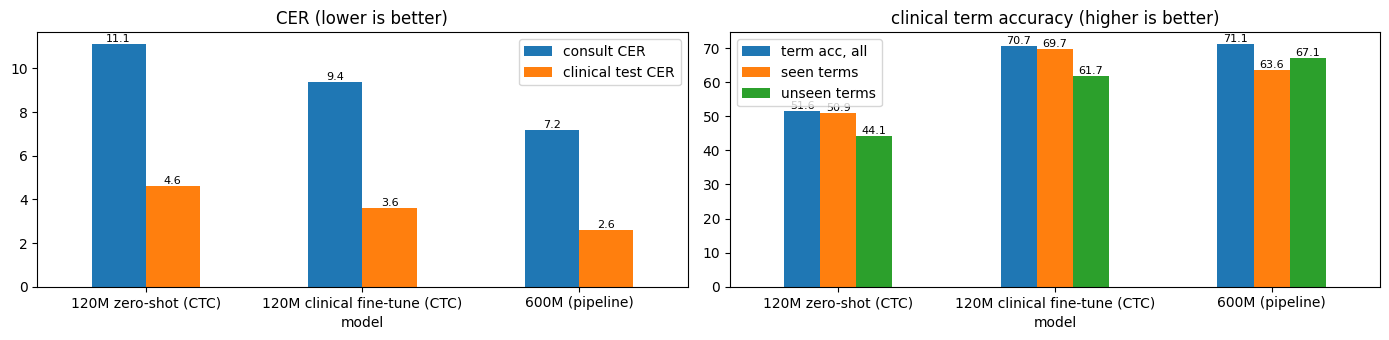

In [21]:
if RUN_120M or RUN_CLINICAL_FINETUNE:
    cmp_rows = []
    for name, c_run, t_run in [("120M zero-shot (CTC)", "zs_indicconformer120m_ctc_consult", "tts_sent_ic120m_zs_ctc"),
                               ("120M clinical fine-tune (CTC)", "ft_icft120m_ctc_consult", "tts_sent_ic120m_ft_ctc"),
                               ("600M (pipeline)", "zs_indicconformer600m_consult", "tts_sent_indicconformer")]:
        t = tts(NEW, t_run)
        cmp_rows.append({"model": name, "consult CER": consult_cer(NEW, c_run), "clinical test CER": t.get("ALL", {}).get("CER%"),
                         "term acc, all": t.get("ALL", {}).get("term_acc%"), "seen terms": t.get("term_acc_seen_in_training%"),
                         "unseen terms": t.get("term_acc_unseen%")})
    cmp_df = pd.DataFrame(cmp_rows).set_index("model")
    display(cmp_df)
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
    cmp_df[["consult CER", "clinical test CER"]].plot.bar(ax=ax[0], rot=0, title="CER (lower is better)")
    cmp_df[["term acc, all", "seen terms", "unseen terms"]].plot.bar(ax=ax[1], rot=0, title="clinical term accuracy (higher is better)")
    for a in ax:
        for c in a.containers: a.bar_label(c, fmt="%.1f", fontsize=8)
    plt.tight_layout(); plt.show()

## Summary

All checks in one table. ✗ = outside the tolerance.

In [22]:
summary = pd.DataFrame(CHECKS)
print(f"{(summary.match == '✓').sum()} / {len(summary)} results reproduced within tolerance")
summary

27 / 27 results reproduced within tolerance


,result,submitted,reproduced,tolerance,match
0,whisper-small zero-shot WER (OpenSLR test),144.13,144.05,0.5,✓
1,whisper-small zero-shot CER,135.74,135.67,0.5,✓
2,zero-shot: % outputs in the wrong script,98.50,98.50,1.0,✓
3,whisper-small FINE-TUNED WER (OpenSLR test),66.36,66.61,0.3,✓
4,whisper-small FINE-TUNED CER,21.44,21.48,0.3,✓
5,"non-speech clips that produce text, no_gate (o...",19.00,19.00,1.0,✓
6,"non-speech clips that produce text, with_vad_g...",0.00,0.00,1.0,✓
7,"consult CER, ft_consult",41.60,41.60,3.0,✓
8,"consult CER, ft_consult_tok440",39.20,39.20,3.0,✓
9,"consult CER, ft_consult_tok440_vadgate",39.20,39.20,3.0,✓


## Download the outputs

In [23]:
paths = ['results/task2', 'data/asr', 'data/tts_train']
with zipfile.ZipFile('/content/outputs.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for rel in paths:
        for p in [Path(REPO, rel)] if Path(REPO, rel).is_file() else Path(REPO, rel).rglob('*'):
            if p.is_file():
                z.write(p, p.relative_to(REPO))
    z.writestr('checks.csv', pd.DataFrame(CHECKS).to_csv(index=False))
from google.colab import files
files.download('/content/outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>